# Predicting Air Pressure System Failures in Scania Trucks
### Support Vector Machines 

This notebook builds a failure classifier for the Air Pressure System (APS) of heavy Scania trucks. The APS supplies compressed air to things like the brakes and the gearbox, so a failure there isn't something you want to find out about on the motorway.


**What's inside**

1. A look at the data (imbalance, missing values, skewed counters)
2. Preprocessing that doesn't leak information between folds
3. Two SVMs 
   - a **linear SVM** trained in the primal with the Pegasos sub-gradient method
   - a **kernel (RBF) SVM** trained in the dual with Sequential Minimal Optimisation (SMO)
4. A sanity check of both models on a 2D toy problem where you can actually see the margin
5. Hyperparameter tuning with stratified 5-fold cross-validation
6. Picking a decision threshold that minimises the real-world maintenance cost
7. Final results on the held-out test set

## 1. The problem

The positive class (`pos`) is trucks whose failure was caused by a specific APS component. The negative class (`neg`) is trucks that failed for some other reason. The features are 170 anonymised sensor readings: some are single counters and some are bins of histograms (names like `ag_000 ... ag_009`).

Scania defined the cost of getting a prediction wrong like this:

| Predicted \ Actual | pos | neg |
|---|---|---|
| **pos** | – | **10** (unnecessary workshop check) |
| **neg** | **500** (missed failure, possible breakdown) | – |

So missing a real failure is **50 times** more expensive than a false alarm. That single fact drives most of the decisions below: class weights, the decision threshold, and which metric I optimise. The total cost is

$$\text{Total cost} = 10 \cdot FP + 500 \cdot FN$$

and lower is better.

## 2. Setup

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

DATA_DIR = Path("data")
FIG_DIR = Path("figures");  FIG_DIR.mkdir(exist_ok=True)
MODEL_DIR = Path("models"); MODEL_DIR.mkdir(exist_ok=True)

COST_FP, COST_FN = 10, 500   # from the challenge description

# plot styling: one colour per class, kept the same everywhere
NEG_C, POS_C, GREY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ad", "axes.labelcolor": "#2b2b2a",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
    "legend.frameon": False,
})

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")

print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.0.2 | pandas 2.3.3


## 3. Loading the data

Both CSV files start with a 20-line GPL licence header, and missing values are written as the string `"na"`. Pandas handles both if we tell it to.

In [2]:
train_df = pd.read_csv(DATA_DIR / "aps_failure_training_set.csv", skiprows=20, na_values="na")
test_df  = pd.read_csv(DATA_DIR / "aps_failure_test_set.csv",     skiprows=20, na_values="na")

print(f"train: {train_df.shape[0]:,} rows x {train_df.shape[1]} columns")
print(f"test : {test_df.shape[0]:,} rows x {test_df.shape[1]} columns")
train_df.iloc[:5, :12]

train: 60,000 rows x 171 columns
test : 16,000 rows x 171 columns


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,ag_003,ag_004
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,0.0,37250.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,0.0,18254.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,0.0,1648.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,318.0,2212.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,0.0,43752.0


In [3]:
# SVM maths uses labels in {-1, +1}, so convert now and keep it that way
y_train = np.where(train_df.pop("class") == "pos", 1, -1)
y_test  = np.where(test_df.pop("class")  == "pos", 1, -1)

for name, y in [("train", y_train), ("test", y_test)]:
    n_pos = (y == 1).sum()
    print(f"{name:5s}: {n_pos:5d} failures out of {len(y):,}  ({n_pos / len(y):.2%})  ->  1 : {(y == -1).sum() / n_pos:.0f}")

train:  1000 failures out of 60,000  (1.67%)  ->  1 : 59
test :   375 failures out of 16,000  (2.34%)  ->  1 : 42


## 4. Exploratory analysis

### 4.1 Class imbalance

Only about 1.7% of trucks in the training set have an APS failure. A model that always says "no failure" would be 98.3% accurate and completely useless, it would cost 1000 × 500 = 500,000 on the training set. That's why accuracy doesn't appear anywhere in the evaluation.

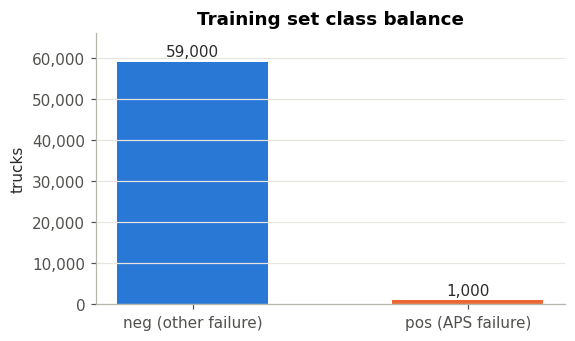

In [4]:
fig, ax = plt.subplots(figsize=(5.5, 3.2))
counts = [(y_train == -1).sum(), (y_train == 1).sum()]
bars = ax.bar(["neg (other failure)", "pos (APS failure)"], counts, color=[NEG_C, POS_C], width=0.55)
for b, c in zip(bars, counts):
    ax.text(b.get_x() + b.get_width() / 2, c + 600, f"{c:,}", ha="center", va="bottom", color="#2b2b2a")
ax.set_ylabel("trucks"); ax.set_title("Training set class balance")
ax.set_ylim(0, 66000); ax.grid(axis="x", visible=False)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
save(fig, "01_class_balance"); plt.show()

### 4.2 Missing values

Missing data is everywhere. A handful of columns are missing for more than 70% of trucks, which is too much to impute honestly, so those get dropped. Everything else gets median imputation later.

columns with any missing value : 169 / 170
columns missing > 50%          : 8
columns missing > 70%          : 7
overall share of missing cells : 8.3%


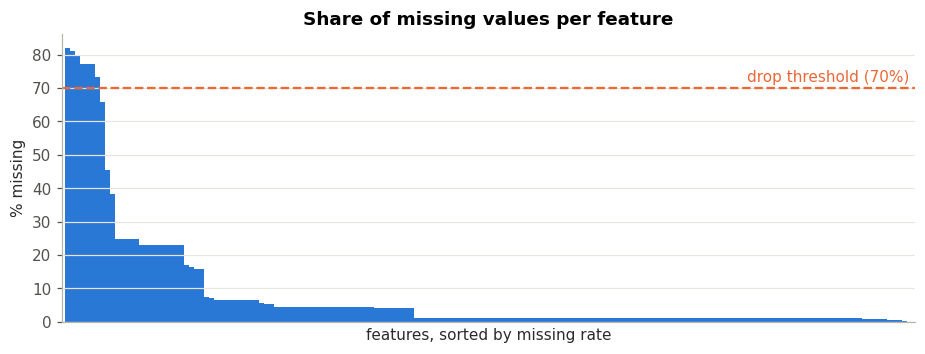

In [5]:
missing = train_df.isna().mean().sort_values(ascending=False)

print(f"columns with any missing value : {(missing > 0).sum()} / {train_df.shape[1]}")
print(f"columns missing > 50%          : {(missing > 0.5).sum()}")
print(f"columns missing > 70%          : {(missing > 0.7).sum()}")
print(f"overall share of missing cells : {train_df.isna().values.mean():.1%}")

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(np.arange(len(missing)), missing.values * 100, color=NEG_C, width=1.0)
ax.axhline(70, color=POS_C, lw=1.5, ls="--")
ax.text(len(missing) - 1, 72, "drop threshold (70%)", ha="right", color=POS_C)
ax.set_xlim(-1, len(missing)); ax.set_xticks([])
ax.set_xlabel("features, sorted by missing rate"); ax.set_ylabel("% missing")
ax.set_title("Share of missing values per feature")
save(fig, "02_missing_values"); plt.show()

Something worth checking: is missingness itself related to the label? If failing trucks report more (or fewer) sensor values, that's a signal.

In [6]:
row_missing = train_df.isna().sum(axis=1)
pd.DataFrame({
    "mean missing per row": [row_missing[y_train == -1].mean(), row_missing[y_train == 1].mean()],
    "median missing per row": [row_missing[y_train == -1].median(), row_missing[y_train == 1].median()],
}, index=["neg", "pos"]).round(1)

,mean missing per row,median missing per row
neg,13.9,8.0
pos,29.2,20.5


Yes, quite strongly. Failing trucks have roughly **twice as many** missing readings as healthy ones. Median imputation hides this, which is fine for a first model, but it's an obvious idea for future work (add a "number of missing sensors" feature).

### 4.3 Heavily skewed counters

All the features are non-negative counters, and most are extremely right-skewed: a few trucks have values thousands of times larger than the median. SVMs care a lot about distances, so a handful of huge values would dominate everything. A `log1p` transform fixes most of this.

min value in the whole table: 0.0
features with |skewness| > 2 : 160 / 170
median |skewness|            : 17.5


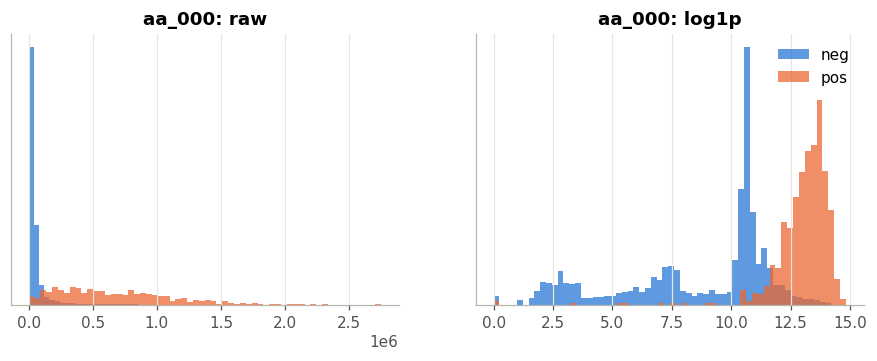

In [7]:
num = train_df.astype(float)
skew = num.skew().abs().sort_values(ascending=False)
print(f"min value in the whole table: {np.nanmin(num.values)}")
print(f"features with |skewness| > 2 : {(skew > 2).sum()} / {len(skew)}")
print(f"median |skewness|            : {skew.median():.1f}")

feat = "aa_000"
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, data, title in [(axes[0], num[feat], f"{feat}: raw"),
                        (axes[1], np.log1p(num[feat]), f"{feat}: log1p")]:
    ax.hist(data[y_train == -1].dropna(), bins=60, color=NEG_C, alpha=0.75, density=True, label="neg")
    ax.hist(data[y_train == 1].dropna(),  bins=60, color=POS_C, alpha=0.75, density=True, label="pos")
    ax.set_title(title); ax.set_yticks([])
axes[1].legend()
save(fig, "03_log_transform"); plt.show()

After the log transform the two classes separate quite clearly on `aa_000` alone. That's encouraging: a large part of the signal is "how much has this truck been used / stressed", which is roughly linear in log space.

### 4.4 Which single features carry the most signal?

A quick univariate check: the correlation between each (log-transformed) feature and the ±1 label. Point-biserial correlation is just Pearson correlation with a binary variable, so it's a one-liner in NumPy.

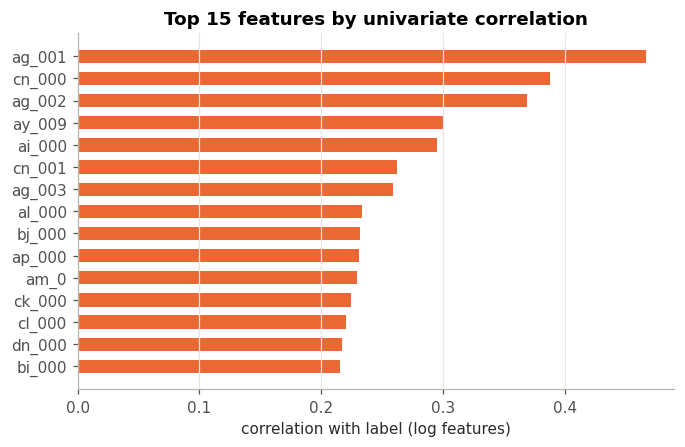

In [8]:
logged = np.log1p(num.fillna(num.median()))
yc = y_train - y_train.mean()
Xc = logged - logged.mean()
corr = (Xc.mul(yc, axis=0).sum() / (np.sqrt((Xc ** 2).sum()) * np.sqrt((yc ** 2).sum()))).dropna()
top = corr.abs().sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(top.index[::-1], corr[top.index[::-1]], color=POS_C, height=0.6)
ax.set_xlabel("correlation with label (log features)")
ax.set_title("Top 15 features by univariate correlation")
ax.grid(axis="y", visible=False)
save(fig, "04_top_correlations"); plt.show()

The strongest single feature (`ag_001`, a histogram bin) reaches about 0.46, and there's a long tail of features around 0.2 to 0.3. Every one of the top 15 is positive: more activity on these counters means more risk. Many are bins of the same histogram, so they're also correlated with each other. No single feature solves the problem, but there's plenty of signal spread across many of them, which is a good setting for a regularised linear model. A kernel model might also pick up interactions between them.

## 5. Preprocessing

The pipeline is deliberately simple:

1. **Drop** columns with more than 70% missing values, plus any constant column (there's one: `cd_000`).
2. **Impute** remaining gaps with the column median (robust to the huge outliers).
3. **`log1p`** every feature to tame the skew.
4. **Standardise** to zero mean and unit variance, so that no feature dominates the kernel distance or the regulariser.

One important detail: the imputer and scaler must be fitted **only on the training part of each fold**. If I fitted them on the full training set before cross-validation, the validation folds would leak into the medians and means. It's a small leak here, but there's no reason to have it at all. So the preprocessing lives inside a small class that gets re-fitted for every fold.

In [9]:
missing_rate = train_df.isna().mean()
DROP_COLS = sorted(set(missing_rate[missing_rate > 0.7].index) | set(train_df.columns[train_df.nunique() <= 1]))
FEATURES = [c for c in train_df.columns if c not in DROP_COLS]
print(f"dropping {len(DROP_COLS)} columns: {DROP_COLS}")
print(f"keeping {len(FEATURES)} features")


class Preprocessor:
    # median impute -> log1p -> standardise. sklearn is only used here.

    def fit(self, df):
        self.imputer = SimpleImputer(strategy="median")
        self.scaler = StandardScaler()
        X = self.imputer.fit_transform(df[FEATURES])
        self.scaler.fit(np.log1p(np.clip(X, 0, None)))
        return self

    def transform(self, df):
        X = self.imputer.transform(df[FEATURES])
        return self.scaler.transform(np.log1p(np.clip(X, 0, None)))

    def fit_transform(self, df):
        return self.fit(df).transform(df)

dropping 8 columns: ['ab_000', 'bn_000', 'bo_000', 'bp_000', 'bq_000', 'br_000', 'cd_000', 'cr_000']
keeping 162 features


## 6. The models

### 6.1 Metrics

First, the evaluation tools.

The threshold search deserves a note. An SVM outputs a real-valued score $f(x)$, and by default we'd predict "failure" when $f(x) \ge 0$. But since a missed failure costs 50× more than a false alarm, the best cut-off is almost certainly lower than 0. `cost_curve` sorts the scores once and uses cumulative sums to get the cost at *every* possible threshold in $O(n \log n)$, then returns the one with the lowest cost.

In [10]:
def confusion(y_true, y_pred):
    tp = int(np.sum((y_pred == 1) & (y_true == 1)))
    tn = int(np.sum((y_pred == -1) & (y_true == -1)))
    fp = int(np.sum((y_pred == 1) & (y_true == -1)))
    fn = int(np.sum((y_pred == -1) & (y_true == 1)))
    return tp, fp, fn, tn


def total_cost(y_true, y_pred):
    _, fp, fn, _ = confusion(y_true, y_pred)
    return COST_FP * fp + COST_FN * fn


def classification_summary(y_true, scores, threshold):
    y_pred = np.where(scores >= threshold, 1, -1)
    tp, fp, fn, tn = confusion(y_true, y_pred)
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    return {
        "cost": COST_FP * fp + COST_FN * fn,
        "FP": fp, "FN": fn, "TP": tp, "TN": tn,
        "precision": precision,
        "recall": recall,
        "f1": 2 * precision * recall / max(precision + recall, 1e-12),
        "roc_auc": roc_auc(y_true, scores),
    }


def roc_curve(y_true, scores):
    order = np.argsort(-scores, kind="mergesort")
    s, yt = scores[order], y_true[order]
    last_of_tie = np.r_[np.where(np.diff(s) != 0)[0], len(s) - 1]
    tps = np.cumsum(yt == 1)[last_of_tie]
    fps = np.cumsum(yt == -1)[last_of_tie]
    tpr = np.r_[0, tps / tps[-1]]
    fpr = np.r_[0, fps / fps[-1]]
    return fpr, tpr


def roc_auc(y_true, scores):
    fpr, tpr = roc_curve(y_true, scores)
    return float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2))   # trapezoid rule


def pr_curve(y_true, scores):
    order = np.argsort(-scores, kind="mergesort")
    yt = y_true[order]
    tp = np.cumsum(yt == 1); fp = np.cumsum(yt == -1)
    precision = tp / (tp + fp)
    recall = tp / tp[-1]
    return recall, precision


def cost_curve(y_true, scores):
    # cost of the rule "predict pos if score >= t" for every distinct t
    order = np.argsort(-scores, kind="mergesort")
    s, yt = scores[order], y_true[order]
    n_pos = int((y_true == 1).sum())
    tp = np.cumsum(yt == 1); fp = np.cumsum(yt == -1)
    last_of_tie = np.r_[np.where(np.diff(s) != 0)[0], len(s) - 1]
    costs = COST_FP * fp[last_of_tie] + COST_FN * (n_pos - tp[last_of_tie])
    thresholds = s[last_of_tie]
    return thresholds, costs


def best_threshold(y_true, scores):
    t, c = cost_curve(y_true, scores)
    k = int(np.argmin(c))
    # put the cut halfway to the next lower score, rather than right on a training point
    t_best = (t[k] + t[k + 1]) / 2 if k + 1 < len(t) else t[k] - 1e-6
    return float(t_best), int(c[k])

### 6.2 Linear SVM: primal problem, Pegasos solver

The soft-margin linear SVM minimises a regularised hinge loss:

$$\min_{w,\,b}\;\; \frac{\lambda}{2}\lVert w\rVert^2 \;+\; \frac{1}{n}\sum_{i=1}^{n} c_i \,\max\bigl(0,\; 1 - y_i (w^\top x_i + b)\bigr)$$

The first term keeps the margin wide; the second punishes points that are on the wrong side of the margin. $c_i$ is a class weight, bigger for failures so the model doesn't just ignore the minority class.

The hinge loss isn't differentiable at the kink, but it has a **sub-gradient**. For a mini-batch $B$, only the points that violate the margin ($y_i f(x_i) < 1$) contribute:

$$\nabla_w = \lambda w - \frac{1}{|B|}\sum_{i \in B,\; y_i f(x_i) < 1} c_i\, y_i\, x_i \qquad \nabla_b = -\frac{1}{|B|}\sum_{i \in B,\; y_i f(x_i) < 1} c_i\, y_i$$

Pegasos (Shalev-Shwartz et al., 2007) uses the step size $\eta_t = 1/(\lambda t)$ and, after each step, projects $w$ back onto a ball of radius $1/\sqrt{\lambda}$ (the optimum is known to lie inside it). Two small practical tweaks:

- I start the step counter at `t0 = 1000` rather than 1. With $\eta_1 = 1/\lambda$ the first few updates are enormous when $\lambda$ is small.
- The returned weights are the **average** of the iterates over the second half of training. Averaging smooths out the noise from stochastic steps and is standard practice for SGD on non-smooth losses.

In [11]:
class LinearSVM:
    # Soft-margin linear SVM, primal form, mini-batch Pegasos with class weights.

    def __init__(self, lam=1e-4, epochs=20, batch_size=256, pos_weight="balanced", t0=1000, seed=0):
        self.lam = lam
        self.epochs = epochs
        self.batch_size = batch_size
        self.pos_weight = pos_weight
        self.t0 = t0
        self.seed = seed

    def _objective(self, X, y, cw, w, b):
        margins = y * (X @ w + b)
        return 0.5 * self.lam * w @ w + np.mean(cw * np.maximum(0.0, 1.0 - margins))

    def fit(self, X, y):
        n, d = X.shape
        rng = np.random.default_rng(self.seed)

        pw = (y == -1).sum() / (y == 1).sum() if self.pos_weight == "balanced" else self.pos_weight
        cw = np.where(y == 1, pw, 1.0)
        cw = cw / cw.mean()                      # keeps the loss on the same scale as unweighted

        w, b = np.zeros(d), 0.0
        w_avg, b_avg, n_avg = np.zeros(d), 0.0, 0
        radius = 1.0 / np.sqrt(self.lam)
        t = self.t0
        self.history_ = []

        for epoch in range(self.epochs):
            order = rng.permutation(n)                  # reshuffle every epoch
            for start in range(0, n, self.batch_size):
                idx = order[start:start + self.batch_size]
                Xb, yb, cb = X[idx], y[idx], cw[idx]

                eta = 1.0 / (self.lam * t)
                viol = yb * (Xb @ w + b) < 1.0          # points inside the margin or misclassified

                grad_w = self.lam * w - (cb[viol] * yb[viol]) @ Xb[viol] / len(idx)
                grad_b = -np.sum(cb[viol] * yb[viol]) / len(idx)
                w -= eta * grad_w
                b -= eta * grad_b

                norm = np.linalg.norm(w)                # Pegasos projection step
                if norm > radius:
                    w *= radius / norm

                if epoch >= self.epochs // 2:           # running average of the iterates
                    n_avg += 1
                    w_avg += (w - w_avg) / n_avg
                    b_avg += (b - b_avg) / n_avg
                t += 1

            self.history_.append(self._objective(X, y, cw, w, b))

        self.w, self.b = w_avg, b_avg
        self.final_objective_ = self._objective(X, y, cw, self.w, self.b)
        return self

    def decision_function(self, X):
        return X @ self.w + self.b

    def predict(self, X, threshold=0.0):
        return np.where(self.decision_function(X) >= threshold, 1, -1)

### 6.3 Kernel SVM: dual problem, SMO solver

A linear boundary can only go so far. The kernel SVM works with the **dual** problem, where the data only ever appears through inner products, so we can swap $x_i^\top x_j$ for a kernel $K(x_i, x_j)$:

$$\max_{\alpha}\;\; \sum_i \alpha_i - \frac12 \sum_{i,j} \alpha_i \alpha_j\, y_i y_j\, K(x_i, x_j) \qquad \text{s.t.}\quad 0 \le \alpha_i \le C_i,\;\; \sum_i \alpha_i y_i = 0$$

I use the RBF kernel $K(x, z) = \exp(-\gamma \lVert x - z\rVert^2)$. Class weighting enters through the box constraint: failures get $C_{+} = C \cdot w_{+}$, healthy trucks get $C_{-} = C$.

**SMO** (Platt, 1998) solves this by repeatedly picking just **two** multipliers $\alpha_i, \alpha_j$ and optimising them analytically while holding the rest fixed. Two is the smallest number you can change without breaking $\sum_i \alpha_i y_i = 0$. My implementation follows the version used inside LIBSVM (Fan, Chen & Lin, 2005):

- keep the gradient $G = Q\alpha - \mathbf{1}$ of the (minimisation form of the) dual, where $Q_{ij} = y_i y_j K_{ij}$
- **working set selection:** pick $i$ as the "most violating" index among those that can still move up, and $j$ as the partner giving the largest *second-order* decrease $b_{ij}^2 / a_{ij}$
- solve the 2-variable sub-problem in closed form, clip to the box $[0, C_i] \times [0, C_j]$
- update $G$ using only two kernel rows: $G \mathrel{+}= Q_{:,i}\,\Delta\alpha_i + Q_{:,j}\,\Delta\alpha_j$
- stop when the KKT violation $m(\alpha) - M(\alpha)$ drops below `tol`

The bias comes from the free support vectors ($0 < \alpha_i < C_i$), which sit exactly on the margin.

**Scaling note.** The kernel matrix is $n \times n$. For all 60,000 trucks that's 3.6 billion entries, which won't fit in memory. So the kernel SVM is trained on **every failure plus a random sample of healthy trucks** (12,000 per CV fold, 15,000 for the final model). Throwing away negatives is much cheaper than throwing away positives, and the decision threshold is tuned afterwards on the *full*, untouched validation folds, so the shifted class ratio doesn't bias the final decisions.

In [12]:
def rbf_kernel(A, B, gamma):
    # exp(-gamma * ||a - b||^2), built in place in float32 to keep memory down
    A = np.asarray(A, dtype=np.float32)
    B = np.asarray(B, dtype=np.float32)
    K = A @ B.T
    K *= -2.0
    K += np.einsum("ij,ij->i", A, A)[:, None]
    K += np.einsum("ij,ij->i", B, B)[None, :]
    np.maximum(K, 0.0, out=K)
    K *= -gamma
    np.exp(K, out=K)
    return K


class KernelSVM:
    # Soft-margin SVM with RBF kernel, dual form, SMO with second-order working set selection.

    def __init__(self, C=1.0, gamma="scale", pos_weight=1.0, tol=1e-3, max_iter=100_000):
        self.C = C
        self.gamma = gamma
        self.pos_weight = pos_weight
        self.tol = tol
        self.max_iter = max_iter

    def fit(self, X, y):
        n, d = X.shape
        y = y.astype(np.float64)
        self.gamma_ = 1.0 / (d * X.var()) if self.gamma == "scale" else self.gamma

        K = rbf_kernel(X, X, self.gamma_)
        Cv = np.where(y > 0, self.C * self.pos_weight, self.C)   # per-sample upper bound
        QD = np.ones(n)                                          # K(x, x) = 1 for RBF
        alpha = np.zeros(n)
        G = -np.ones(n)                                          # gradient of 1/2 a'Qa - 1'a at a = 0

        it = 0
        while it < self.max_iter:
            # ---- working set selection (WSS3 from Fan, Chen & Lin 2005) ----
            minus_yG = -y * G
            I_up  = ((y > 0) & (alpha < Cv)) | ((y < 0) & (alpha > 0))
            I_low = ((y < 0) & (alpha < Cv)) | ((y > 0) & (alpha > 0))

            score_up = np.where(I_up, minus_yG, -np.inf)
            i = int(np.argmax(score_up))
            m_alpha = score_up[i]
            M_alpha = np.min(np.where(I_low, minus_yG, np.inf))
            if m_alpha - M_alpha < self.tol:                     # KKT conditions met
                break

            Ki = K[i].astype(np.float64)
            b_it = m_alpha - minus_yG
            a_it = QD[i] + QD - 2.0 * Ki
            a_it = np.where(a_it > 0, a_it, 1e-12)
            cand = I_low & (b_it > 0)
            j = int(np.argmin(np.where(cand, -(b_it ** 2) / a_it, np.inf)))
            Kj = K[j].astype(np.float64)

            # ---- analytic solution of the 2-variable sub-problem, then clip ----
            Ci, Cj = Cv[i], Cv[j]
            ai_old, aj_old = alpha[i], alpha[j]
            if y[i] != y[j]:
                quad = max(QD[i] + QD[j] - 2.0 * Ki[j], 1e-12)
                delta = (-G[i] - G[j]) / quad
                diff = ai_old - aj_old
                alpha[i] += delta; alpha[j] += delta
                if diff > 0:
                    if alpha[j] < 0: alpha[j] = 0.0; alpha[i] = diff
                else:
                    if alpha[i] < 0: alpha[i] = 0.0; alpha[j] = -diff
                if diff > Ci - Cj:
                    if alpha[i] > Ci: alpha[i] = Ci; alpha[j] = Ci - diff
                else:
                    if alpha[j] > Cj: alpha[j] = Cj; alpha[i] = Cj + diff
            else:
                quad = max(QD[i] + QD[j] - 2.0 * Ki[j], 1e-12)
                delta = (G[i] - G[j]) / quad
                total = ai_old + aj_old
                alpha[i] -= delta; alpha[j] += delta
                if total > Ci:
                    if alpha[i] > Ci: alpha[i] = Ci; alpha[j] = total - Ci
                else:
                    if alpha[j] < 0: alpha[j] = 0.0; alpha[i] = total
                if total > Cj:
                    if alpha[j] > Cj: alpha[j] = Cj; alpha[i] = total - Cj
                else:
                    if alpha[i] < 0: alpha[i] = 0.0; alpha[j] = total

            # ---- gradient update needs only two kernel rows ----
            G += y * (y[i] * Ki * (alpha[i] - ai_old) + y[j] * Kj * (alpha[j] - aj_old))
            it += 1

        # bias from the free support vectors (they lie exactly on the margin)
        free = (alpha > 1e-8) & (alpha < Cv - 1e-8)
        yG = y * G
        if free.any():
            rho = yG[free].mean()
        else:
            ub = np.max(np.where(I_low, yG, -np.inf)); lb = np.min(np.where(I_up, yG, np.inf))
            rho = (ub + lb) / 2
        self.b = -rho

        sv = alpha > 1e-8
        self.alpha = alpha
        self.support_ = np.where(sv)[0]
        self.sv_X = X[sv]
        self.sv_coef = (alpha * y)[sv]                  # alpha_i * y_i
        self.n_iter_ = it
        self.kkt_gap_ = m_alpha - M_alpha
        self.n_free_ = int(free.sum())
        self.n_bounded_ = int(sv.sum() - free.sum())
        self.dual_constraint_ = float(np.dot(alpha, y))   # should be ~0
        return self

    def decision_function(self, X, chunk=4000):
        out = np.empty(len(X))
        for s in range(0, len(X), chunk):
            out[s:s + chunk] = rbf_kernel(X[s:s + chunk], self.sv_X, self.gamma_) @ self.sv_coef + self.b
        return out

    def predict(self, X, threshold=0.0):
        return np.where(self.decision_function(X) >= threshold, 1, -1)

### 6.4 Sanity check on a 2D toy problem

Before throwing 60,000 trucks at code I wrote myself, I want to *see* that it behaves like an SVM. Two interleaving half-moons (generated with NumPy, not `make_moons`) are a classic test: a straight line can't separate them, an RBF kernel should.

What to look for:
- the solid line is the decision boundary $f(x) = 0$, the dashed lines are the margins $f(x) = \pm 1$
- circled points are the support vectors, and they should sit on or inside the margins
- the dual constraint $\sum_i \alpha_i y_i$ should be (numerically) zero

linear: train acc = 0.870
RBF   : train acc = 0.997 | 104 SMO iterations | 20 support vectors | sum(alpha*y) = -1.42e-14 | KKT gap = 8.3e-04


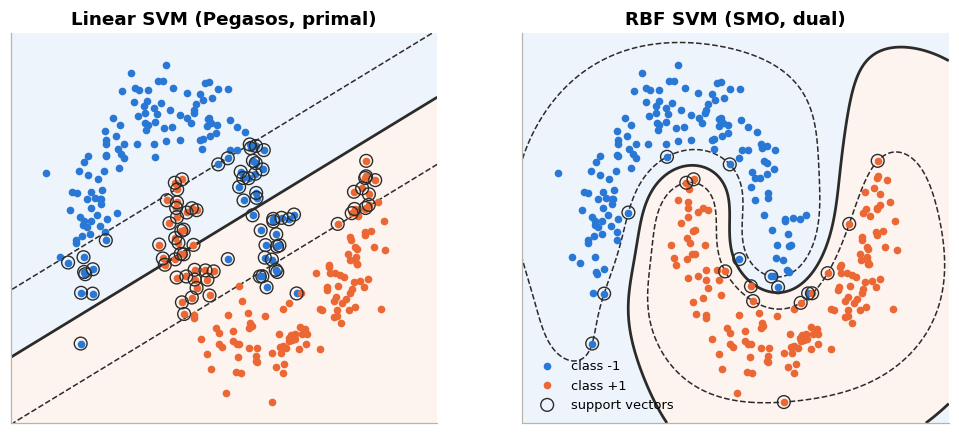

In [13]:
def two_moons(n=300, noise=0.15, seed=0):
    rng = np.random.default_rng(seed)
    n1 = n // 2
    t1 = rng.uniform(0, np.pi, n1); t2 = rng.uniform(0, np.pi, n - n1)
    upper = np.c_[np.cos(t1), np.sin(t1)]
    lower = np.c_[1 - np.cos(t2), 0.5 - np.sin(t2)]
    X = np.vstack([upper, lower]) + rng.normal(0, noise, (n, 2))
    y = np.r_[-np.ones(n1), np.ones(n - n1)].astype(int)
    return (X - X.mean(0)) / X.std(0), y

Xt, yt = two_moons()
toy_lin = LinearSVM(lam=1e-2, epochs=200, batch_size=32, pos_weight=1.0, t0=100).fit(Xt, yt)
toy_rbf = KernelSVM(C=10, gamma=1.0).fit(Xt, yt)

print(f"linear: train acc = {(toy_lin.predict(Xt) == yt).mean():.3f}")
print(f"RBF   : train acc = {(toy_rbf.predict(Xt) == yt).mean():.3f} | {toy_rbf.n_iter_} SMO iterations | "
      f"{len(toy_rbf.support_)} support vectors | sum(alpha*y) = {toy_rbf.dual_constraint_:.2e} | KKT gap = {toy_rbf.kkt_gap_:.1e}")

xx, yy = np.meshgrid(np.linspace(-2.4, 2.4, 300), np.linspace(-2.4, 2.4, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, model, title in [(axes[0], toy_lin, "Linear SVM (Pegasos, primal)"),
                         (axes[1], toy_rbf, "RBF SVM (SMO, dual)")]:
    Z = model.decision_function(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-1e9, 0, 1e9], colors=[NEG_C, POS_C], alpha=0.08)
    ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors=["#2b2b2a"], linestyles=["--", "-", "--"], linewidths=[1, 1.8, 1])
    ax.scatter(*Xt[yt == -1].T, s=16, color=NEG_C, label="class -1", zorder=3)
    ax.scatter(*Xt[yt == 1].T, s=16, color=POS_C, label="class +1", zorder=3)
    if isinstance(model, KernelSVM):
        ax.scatter(*model.sv_X.T, s=70, facecolors="none", edgecolors="#2b2b2a", linewidths=0.9, label="support vectors", zorder=4)
    else:
        sv = yt * model.decision_function(Xt) <= 1.0
        ax.scatter(*Xt[sv].T, s=70, facecolors="none", edgecolors="#2b2b2a", linewidths=0.9, label="on/inside margin", zorder=4)
    ax.set_title(title); ax.set_xlim(-2.4, 2.4); ax.set_ylim(-2.4, 2.4); ax.grid(False)
    ax.set_xticks([]); ax.set_yticks([])
axes[1].legend(loc="lower left", fontsize=8.5)
save(fig, "05_toy_decision_boundaries"); plt.show()

Both models behave exactly like they should. The linear SVM finds the best straight line it can, and the RBF SVM wraps around the moons. Support vectors only appear on or inside the margin, and $\sum_i \alpha_i y_i$ is zero up to floating-point noise, so the equality constraint is respected throughout SMO.

## 7. Cross-validation setup

To tune hyperparameters and the decision threshold I use **stratified 5-fold cross-validation** on the full training set. Stratification keeps the 1:59 ratio in every fold, so each fold gets exactly 200 failures.

The workflow for every model:

1. for each fold: fit the preprocessor on the other 4 folds, train the SVM, score the held-out fold
2. stitch the held-out scores together into one **out-of-fold (OOF)** score per truck
3. choose hyperparameters by the **minimum cost on the OOF scores**, with the threshold optimised for each candidate

Choosing the threshold on OOF scores means it is tuned on all 1,000 failures rather than on a small hold-out set. That matters a lot here: with only ~200 positives in a single validation split, the cost-optimal threshold jumps around noticeably.

The test set is not touched until the very end.

In [14]:
N_FOLDS = 5

def stratified_folds(y, k=N_FOLDS, seed=SEED):
    rng = np.random.default_rng(seed)
    fold = np.empty(len(y), dtype=int)
    for cls in np.unique(y):
        idx = np.where(y == cls)[0]
        rng.shuffle(idx)
        fold[idx] = np.arange(len(idx)) % k
    return fold

fold_id = stratified_folds(y_train)
print(pd.crosstab(fold_id, np.where(y_train == 1, "pos", "neg"), rownames=["fold"], colnames=["class"]))

# Preprocess each fold once and cache it, so the grid searches don't repeat the work
t0 = time.time()
FOLDS = []
for k in range(N_FOLDS):
    tr_idx, va_idx = np.where(fold_id != k)[0], np.where(fold_id == k)[0]
    prep = Preprocessor().fit(train_df.iloc[tr_idx])
    FOLDS.append({
        "X_tr": prep.transform(train_df.iloc[tr_idx]), "y_tr": y_train[tr_idx],
        "X_va": prep.transform(train_df.iloc[va_idx]), "va_idx": va_idx,
    })
print(f"\npreprocessed {N_FOLDS} folds in {time.time() - t0:.1f}s, feature matrix width = {FOLDS[0]['X_tr'].shape[1]}")


def undersample_negatives(y, n_neg, seed):
    # keep every failure, plus n_neg randomly chosen healthy trucks
    rng = np.random.default_rng(seed)
    pos = np.where(y == 1)[0]
    neg = rng.choice(np.where(y == -1)[0], size=min(n_neg, (y == -1).sum()), replace=False)
    return np.sort(np.r_[pos, neg])


def out_of_fold_scores(make_model, n_neg=None):
    oof = np.empty(len(y_train))
    for k, f in enumerate(FOLDS):
        X, y = f["X_tr"], f["y_tr"]
        if n_neg is not None:
            keep = undersample_negatives(y, n_neg, seed=k)
            X, y = X[keep], y[keep]
        oof[f["va_idx"]] = make_model().fit(X, y).decision_function(f["X_va"])
    return oof

class    neg  pos
fold             
0      11800  200
1      11800  200
2      11800  200
3      11800  200
4      11800  200

preprocessed 5 folds in 5.1s, feature matrix width = 162


## 8. Linear SVM

The only real hyperparameter is the regularisation strength $\lambda$ (smaller $\lambda$ = less regularisation = harder margin). Class weights are set to "balanced", meaning each failure counts 59× as much as a healthy truck in the loss.

In [15]:
linear_results = []
linear_oof = {}
for lam in [1e-1, 3e-2, 1e-2, 1e-3, 1e-4]:
    t0 = time.time()
    oof = out_of_fold_scores(lambda: LinearSVM(lam=lam, epochs=20))
    thr, cost = best_threshold(y_train, oof)
    linear_oof[lam] = oof
    linear_results.append({"lambda": lam, "cv_cost": cost, "threshold": round(thr, 3),
                           "cv_roc_auc": round(roc_auc(y_train, oof), 4), "time_s": round(time.time() - t0, 1)})

linear_table = pd.DataFrame(linear_results).sort_values("cv_cost")
best_lin = linear_table.iloc[0]
BEST_LAMBDA = float(best_lin["lambda"])
print(f"best lambda = {BEST_LAMBDA:g}  ->  CV cost {int(best_lin['cv_cost']):,}")
linear_table

best lambda = 0.01  ->  CV cost 48,900


,lambda,cv_cost,threshold,cv_roc_auc,time_s
2,0.0100,48900,-0.199,0.9847,7.7
1,0.0300,49310,0.012,0.9843,7.4
3,0.0010,49390,0.943,0.9845,7.6
4,0.0001,49970,5.430,0.9841,7.4
0,0.1000,56690,0.058,0.9826,7.8


A quick look at convergence. The blue line is the primal objective of the *current* iterate at the end of each epoch, and the dashed line is the objective of the *averaged* weights that the model actually returns.

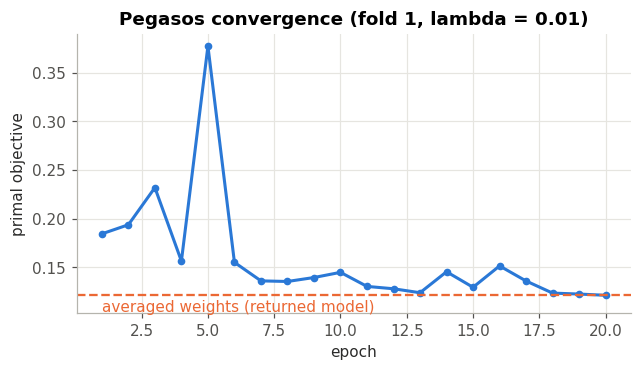

In [16]:
f0 = FOLDS[0]
demo = LinearSVM(lam=BEST_LAMBDA, epochs=20).fit(f0["X_tr"], f0["y_tr"])

fig, ax = plt.subplots(figsize=(6.5, 3.3))
ax.plot(np.arange(1, len(demo.history_) + 1), demo.history_, color=NEG_C, lw=2, marker="o", ms=4)
ax.axhline(demo.final_objective_, color=POS_C, lw=1.5, ls="--")
ax.text(1, demo.final_objective_ * 0.97, "averaged weights (returned model)", va="top", ha="left", color=POS_C)
ax.set_ylim(demo.final_objective_ * 0.85, None)
ax.set_xlabel("epoch"); ax.set_ylabel("primal objective")
ax.set_title(f"Pegasos convergence (fold 1, lambda = {BEST_LAMBDA:g})")
save(fig, "06_pegasos_convergence"); plt.show()

This plot is a nice illustration of *why* iterate averaging is there. Single stochastic sub-gradient steps make the objective jump around, especially early on when the step size $1/(\lambda t)$ is still large (see the spike around epoch 5). The iterates settle down in the second half, and the average of those iterates lands at (or below) the best single iterate, without us having to know in advance which epoch that would be.

## 9. Kernel (RBF) SVM

Three knobs here:

- **C**: how much to penalise margin violations (bigger = tighter fit)
- **γ**: the width of the RBF bump (bigger = more local, wigglier boundary)
- **pos_weight**: extra weight on failures, applied as $C_{+} = C \cdot \text{pos\_weight}$

Because the training subset already has a much less extreme class ratio (≈1:15 instead of 1:59), I only need a modest positive weight. For reference, the `"scale"` heuristic gives $\gamma = 1 / (d \cdot \mathrm{Var}(X)) \approx 1/162 \approx 0.006$, so the grid covers values around and below that.


In [17]:
N_NEG_CV = 12_000      # healthy trucks sampled per CV fold
param_grid = [(C, g, pw) for C in [0.5, 1, 2] for g in [0.001, 0.002, 0.004, 0.008] for pw in [5, 10]]

kernel_results = []
kernel_oof = {}
t_all = time.time()
for C, g, pw in param_grid:
    t0 = time.time()
    oof = out_of_fold_scores(lambda: KernelSVM(C=C, gamma=g, pos_weight=pw), n_neg=N_NEG_CV)
    thr, cost = best_threshold(y_train, oof)
    kernel_oof[(C, g, pw)] = oof
    kernel_results.append({"C": C, "gamma": g, "pos_weight": pw, "cv_cost": cost, "threshold": round(thr, 3),
                           "cv_roc_auc": round(roc_auc(y_train, oof), 4), "time_s": round(time.time() - t0, 1)})

kernel_table = pd.DataFrame(kernel_results).sort_values("cv_cost").reset_index(drop=True)
best_k = kernel_table.iloc[0]
BEST_KERNEL = (float(best_k["C"]), float(best_k["gamma"]), float(best_k["pos_weight"]))
print(f"grid search finished in {(time.time() - t_all) / 60:.1f} min")
print(f"best: C = {BEST_KERNEL[0]:g}, gamma = {BEST_KERNEL[1]:g}, pos_weight = {BEST_KERNEL[2]:g}  ->  CV cost {int(best_k['cv_cost']):,}")
kernel_table.head(8)

grid search finished in 2.6 min
best: C = 1, gamma = 0.004, pos_weight = 10  ->  CV cost 45,080


,C,gamma,pos_weight,cv_cost,threshold,cv_roc_auc,time_s
0,1.0,0.004,10,45080,-0.448,0.9859,6.8
1,0.5,0.008,10,45080,-0.464,0.9851,6.7
2,2.0,0.008,5,45650,-0.622,0.9853,8.0
3,1.0,0.002,10,45680,-0.437,0.9856,6.4
4,2.0,0.001,5,45680,-0.702,0.9850,5.9
5,2.0,0.002,5,45760,-0.705,0.9861,6.5
6,2.0,0.004,5,45930,-0.688,0.9862,7.3
7,0.5,0.004,10,46120,-0.366,0.9854,6.1


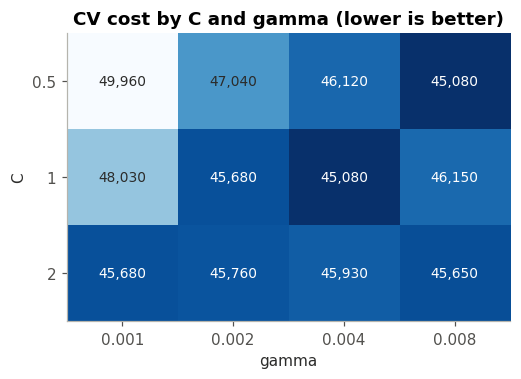

In [18]:
# how sensitive is the CV cost to C and gamma? (best pos_weight for each cell)
pivot = kernel_table.groupby(["C", "gamma"])["cv_cost"].min().unstack()

fig, ax = plt.subplots(figsize=(5.2, 3.4))
im = ax.imshow(pivot.values, cmap="Blues_r", aspect="auto")
ax.set_xticks(range(pivot.shape[1]), [f"{g:g}" for g in pivot.columns])
ax.set_yticks(range(pivot.shape[0]), [f"{c:g}" for c in pivot.index])
ax.set_xlabel("gamma"); ax.set_ylabel("C"); ax.grid(False)
for r in range(pivot.shape[0]):
    for c in range(pivot.shape[1]):
        v = pivot.values[r, c]
        ax.text(c, r, f"{v:,.0f}", ha="center", va="center",
                color="white" if v < pivot.values.mean() else "#2b2b2a", fontsize=9)
ax.set_title("CV cost by C and gamma (lower is better)")
save(fig, "07_kernel_grid"); plt.show()

Apart from the smallest γ with small C (too smooth a boundary), the cost surface is pretty flat: the best eight settings are within about 2.5% of each other. That's reassuring, because it means the result doesn't depend on one lucky hyperparameter combination.

## 10. Choosing the decision threshold

Here's what the threshold actually does. Moving it left catches more failures (fewer 500-cost misses) at the price of more workshop checks (more 10-cost false alarms). The cost curve below is computed on the out-of-fold scores of the two best models.

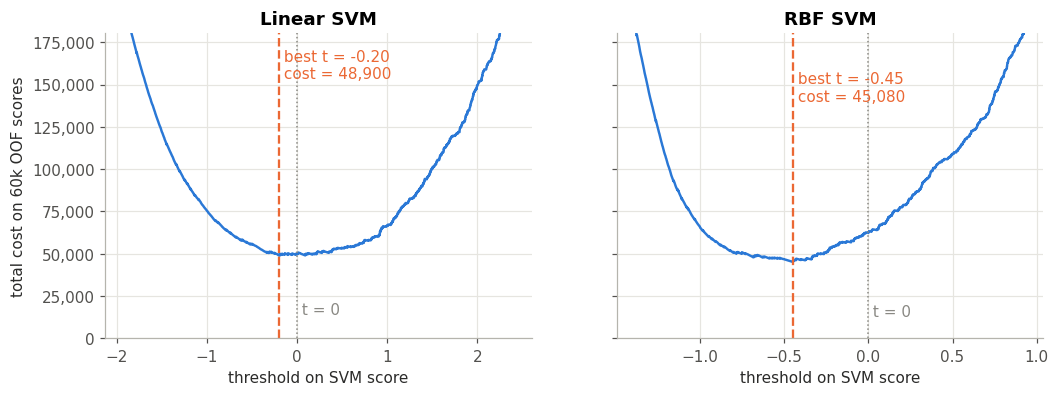

Linear  default t=0: cost  50,030 (FP 2703, FN  46)   tuned t=-0.20: cost  48,900 (FP 3190, FN  34)
RBF     default t=0: cost  62,310 (FP 1281, FN  99)   tuned t=-0.45: cost  45,080 (FP 2308, FN  44)


In [19]:
oof_lin = linear_oof[BEST_LAMBDA]
oof_rbf = kernel_oof[BEST_KERNEL]
THR_LIN, CV_COST_LIN = best_threshold(y_train, oof_lin)
THR_RBF, CV_COST_RBF = best_threshold(y_train, oof_rbf)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, oof, thr, name in [(axes[0], oof_lin, THR_LIN, "Linear SVM"), (axes[1], oof_rbf, THR_RBF, "RBF SVM")]:
    t, c = cost_curve(y_train, oof)
    window = c < 4 * c.min()                    # zoom in on the interesting region
    ax.plot(t[window], c[window], color=NEG_C, lw=1.6)
    ax.axvline(0, color=GREY, lw=1, ls=":")
    ax.text(0, 0.25 * c.min(), " t = 0", color=GREY, va="bottom")
    ax.axvline(thr, color=POS_C, lw=1.5, ls="--")
    ax.text(thr, 3.5 * c.min(), f" best t = {thr:.2f}\n cost = {c.min():,}", color=POS_C, va="top")
    ax.set_ylim(0, 4 * c.min())
    ax.set_xlabel("threshold on SVM score"); ax.set_title(name)
axes[0].set_ylabel("total cost on 60k OOF scores")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
save(fig, "08_threshold_cost_curve"); plt.show()

for name, oof, thr in [("Linear", oof_lin, THR_LIN), ("RBF", oof_rbf, THR_RBF)]:
    s0, st = classification_summary(y_train, oof, 0.0), classification_summary(y_train, oof, thr)
    print(f"{name:6s}  default t=0: cost {s0['cost']:>7,} (FP {s0['FP']:>4}, FN {s0['FN']:>3})   "
          f"tuned t={thr:+.2f}: cost {st['cost']:>7,} (FP {st['FP']:>4}, FN {st['FN']:>3})")

For both models the cost-optimal threshold sits **below** zero: flag a truck even when the model is only moderately confident, because a missed failure is so expensive.

The two models react very differently though. For the RBF SVM, tuning the threshold cuts the CV cost by more than a quarter (62,320 → 45,050). For the linear SVM the default threshold was already close to optimal (50,030 → 48,900). That makes sense: the linear model was trained with fully balanced class weights (59:1), which already pushes its boundary towards the failures. The RBF model only had a 10× weight on a 1:12 subsample, so its raw boundary is more conservative and needs the threshold shift to catch up.

## 11. Final models and test set evaluation

Now the hyperparameters and thresholds are frozen. I retrain each model on the **whole** training set (preprocessor included), then score the test set exactly once.

Based on cross-validation, the **RBF SVM is the selected model** (CV cost 45,050 vs 48,900 for the linear one). I still evaluate both on the test set, since the comparison is interesting.

For the kernel SVM the final training set is all 1,000 failures plus 15,000 healthy trucks. That's 25% more negatives than in each CV fold, which matches the fact that the full training set is 25% bigger than a CV training fold (5/4), so the class ratio the model sees stays the same as during tuning.

In [20]:
final_prep = Preprocessor().fit(train_df)
X_full = final_prep.transform(train_df)
X_test = final_prep.transform(test_df)

t0 = time.time()
final_lin = LinearSVM(lam=BEST_LAMBDA, epochs=20).fit(X_full, y_train)
t_lin = time.time() - t0

N_NEG_FINAL = int(N_NEG_CV * N_FOLDS / (N_FOLDS - 1))
keep = undersample_negatives(y_train, N_NEG_FINAL, seed=SEED)
C, g, pw = BEST_KERNEL
t0 = time.time()
final_rbf = KernelSVM(C=C, gamma=g, pos_weight=pw).fit(X_full[keep], y_train[keep])
t_rbf = time.time() - t0

print(f"linear SVM trained on {len(y_train):,} rows in {t_lin:.1f}s")
print(f"RBF SVM trained on {len(keep):,} rows in {t_rbf:.1f}s: {final_rbf.n_iter_:,} SMO iterations, "
      f"{len(final_rbf.support_):,} support vectors ({final_rbf.n_free_} free, {final_rbf.n_bounded_} at bound), "
      f"KKT gap {final_rbf.kkt_gap_:.1e}")

scores_lin = final_lin.decision_function(X_test)
scores_rbf = final_rbf.decision_function(X_test)

linear SVM trained on 60,000 rows in 2.1s
RBF SVM trained on 16,000 rows in 2.1s: 4,028 SMO iterations, 1,784 support vectors (779 free, 1005 at bound), KKT gap 1.0e-03


In [21]:
rows = []
for name, scores, thr in [("Linear SVM (Pegasos)", scores_lin, THR_LIN), ("RBF SVM (SMO)", scores_rbf, THR_RBF)]:
    for label, t in [("t = 0 (default)", 0.0), (f"t = {thr:+.2f} (tuned)", thr)]:
        s = classification_summary(y_test, scores, t)
        rows.append({"model": name, "threshold": label, "total cost": s["cost"], "FP": s["FP"], "FN": s["FN"],
                     "recall": round(s["recall"], 3), "precision": round(s["precision"], 3),
                     "F1": round(s["f1"], 3), "ROC AUC": round(s["roc_auc"], 4)})
results = pd.DataFrame(rows)
results

,model,threshold,total cost,FP,FN,recall,precision,F1,ROC AUC
0,Linear SVM (Pegasos),t = 0 (default),12820,682,12,0.968,0.347,0.511,0.9912
1,Linear SVM (Pegasos),t = -0.20 (tuned),10980,798,6,0.984,0.316,0.479,0.9912
2,RBF SVM (SMO),t = 0 (default),17000,300,28,0.925,0.536,0.679,0.9915
3,RBF SVM (SMO),t = -0.45 (tuned),11690,569,12,0.968,0.389,0.555,0.9915


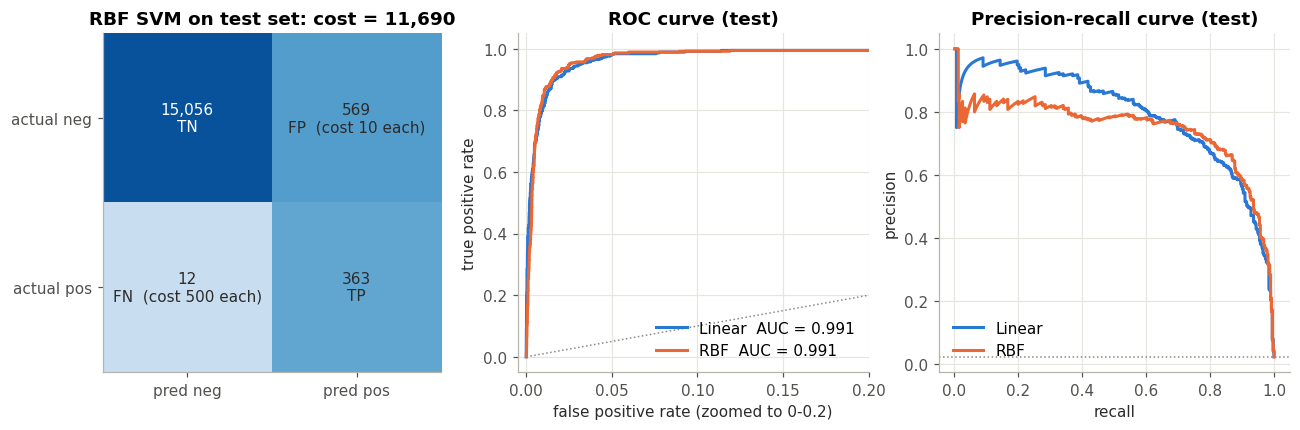

In [22]:
final = classification_summary(y_test, scores_rbf, THR_RBF)
final_lin_s = classification_summary(y_test, scores_lin, THR_LIN)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# confusion matrix of the RBF model
ax = axes[0]
cm = np.array([[final["TN"], final["FP"]], [final["FN"], final["TP"]]])
ax.imshow(np.log1p(cm), cmap="Blues", vmin=0, vmax=np.log1p(cm).max() * 1.15)
labels = [["TN", "FP  (cost 10 each)"], ["FN  (cost 500 each)", "TP"]]
for r in range(2):
    for c in range(2):
        ax.text(c, r, f"{cm[r, c]:,}\n{labels[r][c]}", ha="center", va="center",
                color="white" if cm[r, c] > 1000 else "#2b2b2a", fontsize=10)
ax.set_xticks([0, 1], ["pred neg", "pred pos"]); ax.set_yticks([0, 1], ["actual neg", "actual pos"])
ax.set_title(f"RBF SVM on test set: cost = {final['cost']:,}"); ax.grid(False)

# ROC
ax = axes[1]
for scores, color, name in [(scores_lin, NEG_C, "Linear"), (scores_rbf, POS_C, "RBF")]:
    fpr, tpr = roc_curve(y_test, scores)
    ax.plot(fpr, tpr, color=color, lw=2, label=f"{name}  AUC = {roc_auc(y_test, scores):.3f}")
ax.plot([0, 1], [0, 1], color=GREY, lw=1, ls=":")
ax.set_xlim(-0.005, 0.2)
ax.set_xlabel("false positive rate (zoomed to 0-0.2)"); ax.set_ylabel("true positive rate"); ax.set_title("ROC curve (test)")
ax.legend(loc="lower right")

# precision-recall
ax = axes[2]
for scores, color, name in [(scores_lin, NEG_C, "Linear"), (scores_rbf, POS_C, "RBF")]:
    rec, prec = pr_curve(y_test, scores)
    ax.plot(rec, prec, color=color, lw=2, label=name)
ax.axhline((y_test == 1).mean(), color=GREY, lw=1, ls=":")
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_title("Precision-recall curve (test)")
ax.legend(loc="lower left")

save(fig, "09_test_evaluation"); plt.show()

The largest weights are mostly on single counters (`ci_000`, `aa_000`, `ck_000`, `bt_000`) plus a few histogram bins (`cn_*`, `ay_006`). Interesting detail: a few features get *negative* weights (e.g. `cb_000`, `ax_000`) even though every feature in section 4.4 had a positive correlation with failure. That's the classic effect of correlated inputs. Once the model already knows the overall activity level from the other counters, these features end up acting as corrections. So the weights should be read as "effect given everything else", not as standalone importance.

Since the features are anonymised I can't say what physical quantities these are, but this list is exactly what I'd take to a domain expert at Scania for a sanity check.

## 12. Saving the final model

Everything needed to score a new truck is saved in one `.npz` file: the preprocessing parameters, the support vectors with their coefficients, the kernel width, the bias and the tuned threshold. No pickle, no sklearn objects needed at inference time.

In [23]:
np.savez_compressed(
    MODEL_DIR / "rbf_svm_aps.npz",
    features=np.array(FEATURES),
    impute_median=final_prep.imputer.statistics_,
    scale_mean=final_prep.scaler.mean_,
    scale_std=final_prep.scaler.scale_,
    support_vectors=final_rbf.sv_X.astype(np.float32),
    dual_coef=final_rbf.sv_coef,
    bias=final_rbf.b,
    gamma=final_rbf.gamma_,
    threshold=THR_RBF,
)

# reload and score the test set again with plain NumPy, to prove the file is self-contained
m = np.load(MODEL_DIR / "rbf_svm_aps.npz")
raw = test_df[m["features"].tolist()].to_numpy(dtype=float)
raw = np.where(np.isnan(raw), m["impute_median"], raw)
z = (np.log1p(np.clip(raw, 0, None)) - m["scale_mean"]) / m["scale_std"]
reloaded = rbf_kernel(z, m["support_vectors"], float(m["gamma"])) @ m["dual_coef"] + float(m["bias"])
pred = np.where(reloaded >= float(m["threshold"]), 1, -1)

print(f"saved {(MODEL_DIR / 'rbf_svm_aps.npz').stat().st_size / 1e6:.1f} MB")
print(f"reloaded model test cost: {total_cost(y_test, pred):,}  (matches: {total_cost(y_test, pred) == final['cost']})")

saved 0.7 MB
reloaded model test cost: 11,690  (matches: True)


## 14. Conclusions

**Results on the 16,000-truck test set**

| Model | Threshold | Total cost | False alarms | Missed failures | ROC AUC |
|---|---|---|---|---|---|
| RBF SVM (SMO), CV-selected | −0.45 (tuned) | **11,690** | 569 | 12 | 0.991 |
| Linear SVM (Pegasos) | −0.20 (tuned) | **10,980** | 798 | 6 | 0.991 |
| Predict "no failure" for every truck | – | 187,500 | 0 | 375 | – |

What I take away from this:

- **Both from-scratch SVMs work as intended.** On the toy problem they draw the textbook margins and the SMO solver respects the dual constraints. On the real data both reach a test ROC AUC of about 0.991 and cut the cost of the naive baseline by about 94%.
- **Tuning the threshold for the 10 vs 500 cost matrix matters a lot**, especially for the RBF model, where it brought the test cost down from 17,000 to 11,690 (−31%). For the linear model it went from 12,820 to 10,980 (−14%).
- **CV and test disagree slightly on which model is better.** Cross-validation clearly preferred the RBF SVM (about 8% lower cost on 60,000 trucks), but on the test set the linear SVM came out 710 lower. That's roughly 1.4 missed trucks' worth, i.e. well within the noise you'd expect from a single test set with 375 failures. I kept the CV-based choice, because picking the model after looking at the test set would make the test score meaningless.
- **For production I'd honestly lean towards the linear model.** It trains on all 60k rows in a couple of seconds, has 162 weights instead of ~1,800 support vectors, and its weights can be inspected. The kernel didn't buy enough to justify the extra complexity on this dataset.
